# Tutorial on Global Temperature Trends with Deep Learning

## Predicting global temperature from greenhouse gas emissions

This hands-on tutorial accompanies the [Convolutional Neural Networks](../lectures_ML/DeepLearning/cnn.ipynb) notes. Here we will use a convolutional neural network (CNN) to predict the map of global surface temperature from global emissions of CO2 and CH4. This is based on notebooks developed by Weiwei Zhan and Francesco Immorlano.

In [1]:
import os, tarfile, urllib.request
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
from tensorflow import keras
from tensorflow.keras.layers import Input, Dense, Reshape, Conv2DTranspose

In [2]:
# ClimateBench (Zenodo, CC-BY-4.0): about 900 MB, downloaded once into climatebench_data/
DATA = "climatebench_data/"
for name, check in [("train_val.tar.gz", "inputs_historical.nc"), ("test.tar.gz", "inputs_ssp245.nc")]:
    if not os.path.exists(DATA + check):
        print("downloading", name)
        urllib.request.urlretrieve(f"https://zenodo.org/api/records/7064308/files/{name}/content", name)
        tarfile.open(name).extractall(DATA)
        os.remove(name)

## Visualization of the ClimateBench Data

ClimateBench is a spatial-temporal dataset that contains simulations generated by the NorESM2 climate model. It provides both historical simulations & future projections under different scenarios (e.g., ssp245).

We open every scenario once. `inputs` holds the yearly global CO2 and CH4 emissions, and `tas` holds the yearly maps of surface air temperature change, averaged over the three ensemble members.

In [3]:
scenarios = ["historical", "ssp126", "ssp245", "ssp370", "ssp585", "hist-aer", "hist-GHG"]
inputs = {s: xr.open_dataset(f"{DATA}inputs_{s}.nc") for s in scenarios}
tas = {s: xr.open_dataset(f"{DATA}outputs_{s}.nc").tas.mean("member").drop_vars("quantile") for s in scenarios}

The historical run and the four future scenarios, which make different assumptions about future emissions. Left to right: cumulative CO2 emissions since 1850 (GtCO2), CH4 emissions (GtCH4 per year), and global mean temperature change (°C). The global mean weights each grid cell by the cosine of its latitude, because cells shrink toward the poles.

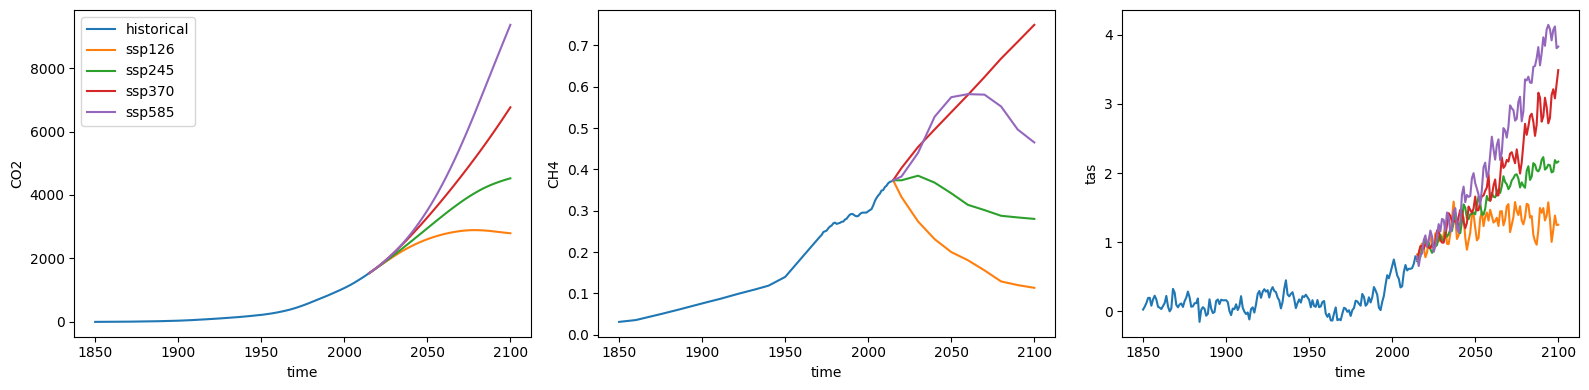

In [4]:
def global_mean(t):
    return t.weighted(np.cos(np.deg2rad(t.lat))).mean(["lat", "lon"])

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for s in ["historical", "ssp126", "ssp245", "ssp370", "ssp585"]:
    inputs[s].CO2.plot(ax=axes[0], label=s)
    inputs[s].CH4.plot(ax=axes[1])
    global_mean(tas[s]).plot(ax=axes[2])
axes[0].legend()
plt.tight_layout()

Temperature change maps for the historical run in 1900, 1950 and 2000, and for ssp370 in 2020, 2050 and 2100.

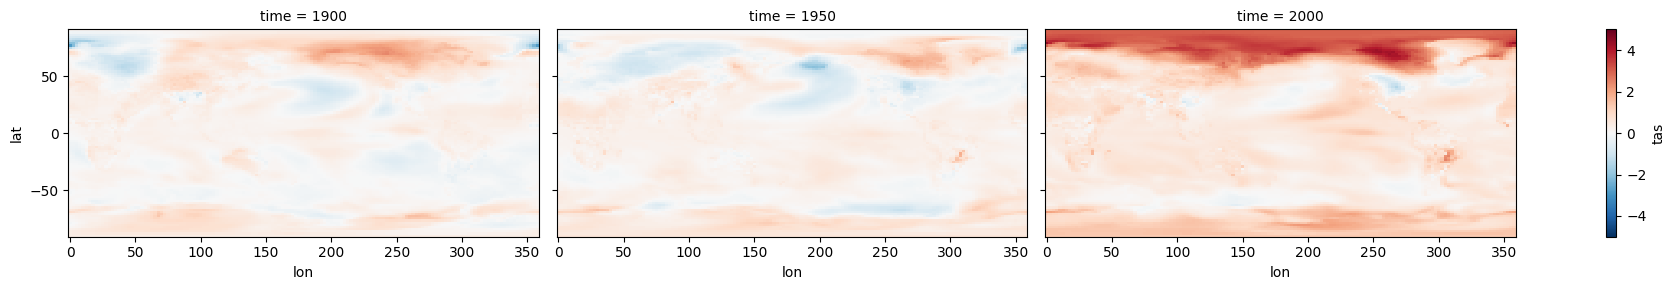

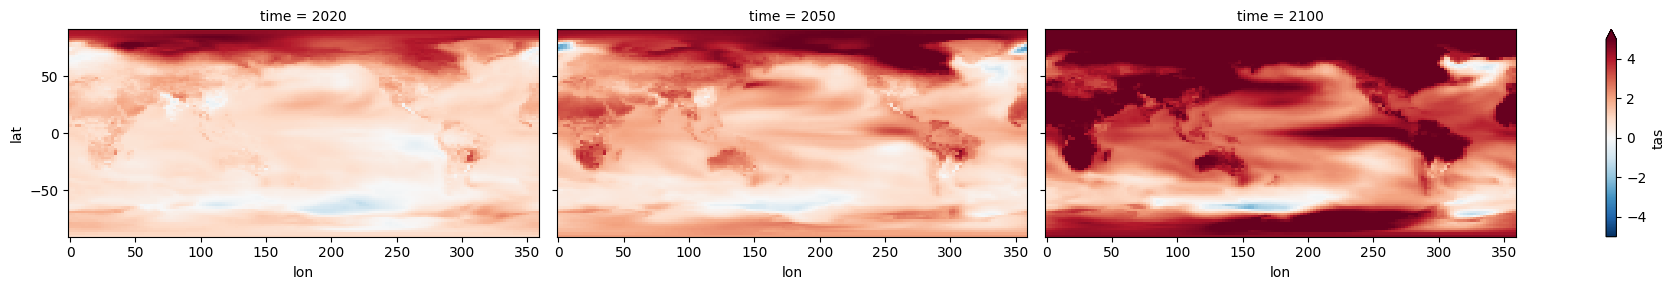

In [5]:
tas["historical"].sel(time=[1900, 1950, 2000]).plot(col="time", aspect=2, center=0, vmax=5)
tas["ssp370"].sel(time=[2020, 2050, 2100]).plot(col="time", aspect=2, center=0, vmax=5)

## Data preprocessing
We will train the CNN using simulations from 3 historical and 3 future scenarios. We will then test the trained CNN on the ssp245 scenario.

Each input is one year's pair of numbers, CO2 and CH4. Each target is that year's 96 × 144 temperature map.

In [6]:
train = ["historical", "ssp585", "ssp126", "ssp370", "hist-aer", "hist-GHG"]

def gases(s):
    return np.column_stack([inputs[s].CO2, inputs[s].CH4])

X_train = np.concatenate([gases(s) for s in train])
y_train = np.concatenate([tas[s] for s in train])
X_test, y_test = gases("ssp245"), tas["ssp245"]

## Data normalization

We standardize the two inputs with the mean and standard deviation of the training set, and use the same numbers for the test set.

In [7]:
mean, std = X_train.mean(axis=0), X_train.std(axis=0)
X_train = (X_train - mean) / std
X_test = (X_test - mean) / std
print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)

(753, 2) (753, 96, 144) (86, 2) (86, 96, 144)


## Define the CNN architecture

The CNN is a decoder. A dense layer turns the two inputs into a coarse 12 × 18 map with 32 channels. Three transposed convolutions with stride 2 then double the map each time, to 24 × 36, 48 × 72 and 96 × 144, and a last layer with one filter gives the temperature map. These settings are for demonstration and are not tuned.

In [8]:
n_filters, kernel_size = 32, 4

model = keras.Sequential([
    Input(shape=(2,)),
    Dense(12 * 18 * n_filters, activation="relu"),
    Reshape((12, 18, n_filters)),
    Conv2DTranspose(n_filters, kernel_size, strides=2, padding="same", activation="relu"),  # 24 x 36
    Conv2DTranspose(n_filters, kernel_size, strides=2, padding="same", activation="relu"),  # 48 x 72
    Conv2DTranspose(n_filters, kernel_size, strides=2, padding="same", activation="relu"),  # 96 x 144
    Conv2DTranspose(1, kernel_size, padding="same"),
])
model.compile(loss="mse", optimizer="adam")
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 6912)              20736     
                                                                 
 reshape (Reshape)           (None, 12, 18, 32)        0         
                                                                 
 conv2d_transpose (Conv2DTra  (None, 24, 36, 32)       16416     
 nspose)                                                         
                                                                 
 conv2d_transpose_1 (Conv2DT  (None, 48, 72, 32)       16416     
 ranspose)                                                       
                                                                 
 conv2d_transpose_2 (Conv2DT  (None, 96, 144, 32)      16416     
 ranspose)                                                       
                                                        

## Train the CNN

Early stopping ends training once the validation loss has not improved for 20 epochs. The validation set is the last 20% of the training rows.

In [9]:
early_stop = keras.callbacks.EarlyStopping(patience=20)
history = model.fit(X_train, y_train, batch_size=64, epochs=100, validation_split=0.2, callbacks=[early_stop])

Epoch 1/100
10/10 [==============================] - 2s 129ms/step - loss: 3.6594 - val_loss: 0.4873
Epoch 2/100
10/10 [==============================] - 1s 118ms/step - loss: 2.6178 - val_loss: 0.5885
Epoch 3/100
10/10 [==============================] - 1s 118ms/step - loss: 1.5954 - val_loss: 0.2744
Epoch 4/100
10/10 [==============================] - 1s 118ms/step - loss: 0.9543 - val_loss: 0.2310
Epoch 5/100
10/10 [==============================] - 1s 118ms/step - loss: 0.7096 - val_loss: 0.2642
Epoch 6/100
10/10 [==============================] - 1s 117ms/step - loss: 0.6330 - val_loss: 0.2632
Epoch 7/100
10/10 [==============================] - 1s 117ms/step - loss: 0.5847 - val_loss: 0.2533
Epoch 8/100
10/10 [==============================] - 1s 117ms/step - loss: 0.5534 - val_loss: 0.2536
Epoch 9/100
10/10 [==============================] - 1s 118ms/step - loss: 0.5306 - val_loss: 0.2471
Epoch 10/100
10/10 [==============================] - 1s 118ms/step - loss: 0.5122 - val_lo

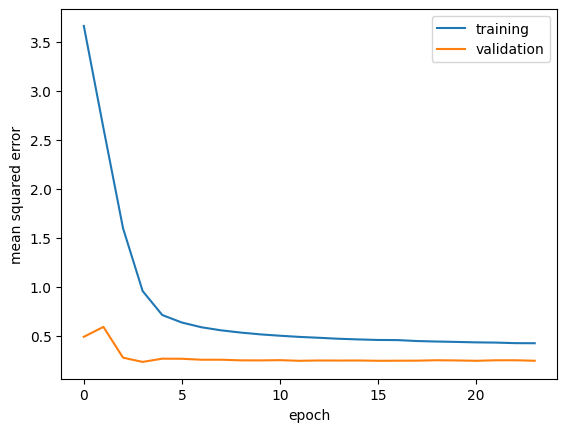

In [10]:
plt.plot(history.history["loss"], label="training")
plt.plot(history.history["val_loss"], label="validation")
plt.xlabel("epoch")
plt.ylabel("mean squared error")
plt.legend()

## Evaluate the trained model

We predict the ssp245 maps and compare them with the climate model. To keep a trained model for later, `model.save("cnn.keras")` writes it to a file and `keras.models.load_model("cnn.keras")` reads it back.

In [11]:
y_pred = y_test.copy(data=model.predict(X_test).reshape(y_test.shape))

3/3 [==============================] - 0s 21ms/step


First we check whether the ML model can capture the spatial distribution of global temperature. First row: CNN prediction. Second row: the climate model.

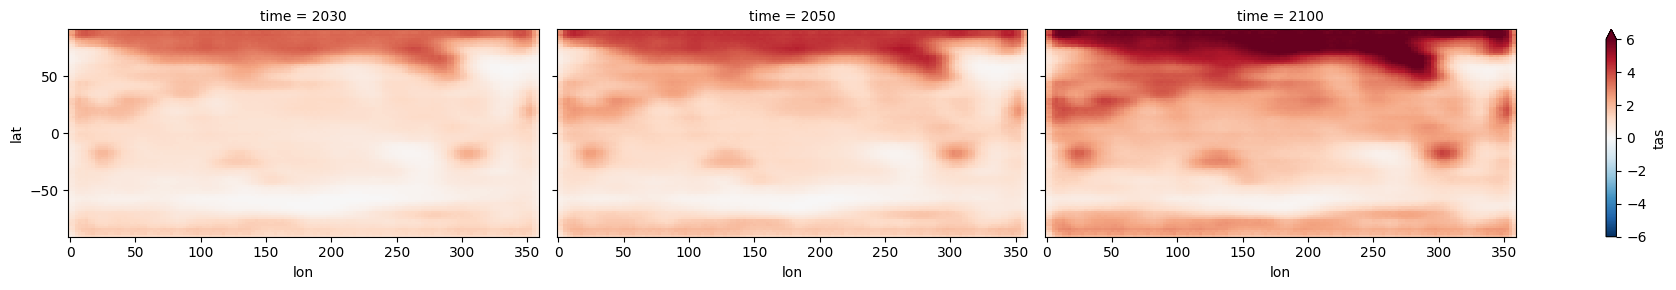

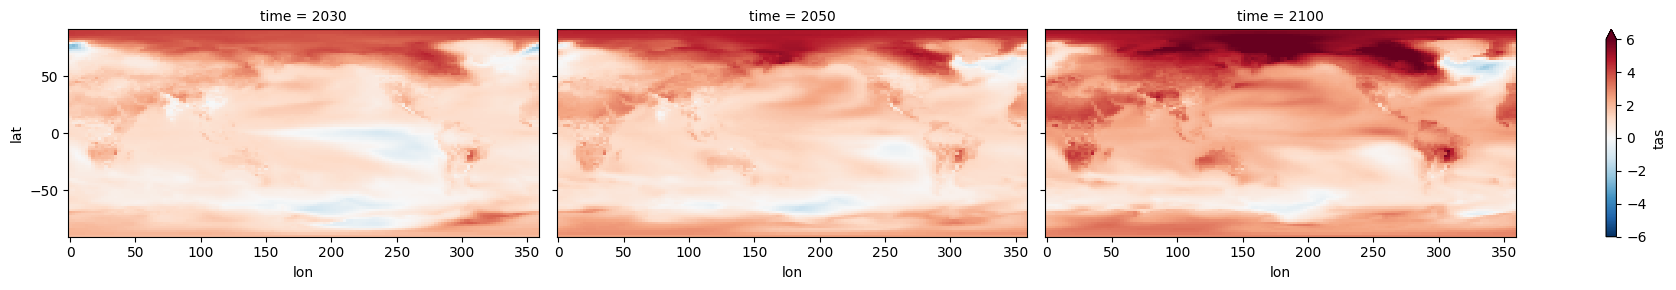

In [12]:
for t in [y_pred, y_test]:
    t.sel(time=[2030, 2050, 2100]).plot(col="time", aspect=2, center=0, vmax=6)

Then we check whether the ML model can reproduce the time series at one location. Here we take NYC, at 40.7° N and 74° W. This grid runs from 0° to 360° E, so 74° W is 286° E.

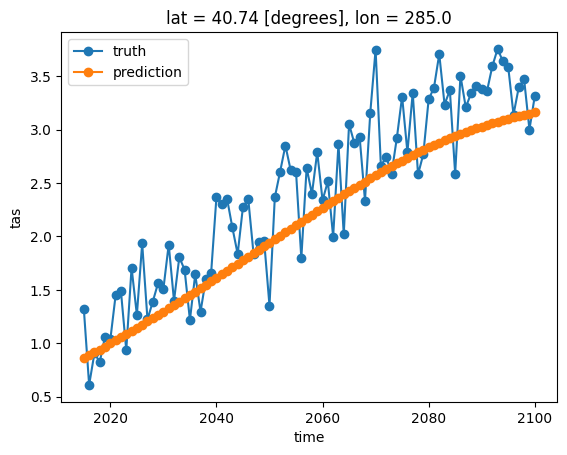

In [13]:
y_test.sel(lat=40.7, lon=286, method="nearest").plot(marker="o", label="truth")
y_pred.sel(lat=40.7, lon=286, method="nearest").plot(marker="o", label="prediction")
plt.legend()

Finally we check whether the ML model can capture the time series of global average temperature, with the same area-weighted mean as above.

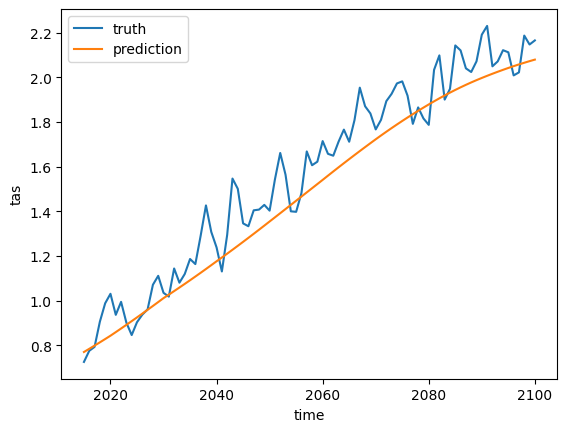

In [14]:
global_mean(y_test).plot(label="truth")
global_mean(y_pred).plot(label="prediction")
plt.legend()

## Try it yourself

1. **Set the random seed.** The CNN starts from random weights (and SGD samples random batches), so results shift slightly run to run. Add `keras.utils.set_random_seed(42)` before building the model and confirm the losses reproduce.
2. **Test on a different scenario.** Retrain on the other scenarios and test on **ssp585** instead of ssp245. Does the emulator do worse when it has to *extrapolate* to a hotter scenario than any it trained on, rather than *interpolate*?
3. **Tune the CNN.** Try a larger `kernel_size`, more `n_filters`, or more up-sampling layers. Can you sharpen the blurry maps without overfitting the small dataset?
4. **Add a metric.** Pass `metrics=['RootMeanSquaredError']` to `model.compile` and watch the RMSE (in °C) alongside the MSE loss during training.

The last two run in seconds and neither retrains a model, so they are good to try in class if there is time.

5. **Read off the architecture, no training.** Rerun *only* the model cell with a different `kernel_size` (try 3 and 8) or a different `n_filters`, and read the summary. Do **not** rerun the training cell. The output stays 96 by 144 whatever the filter size: why? (Look at `padding='same'` and the three stride-2 up-sampling layers.) How does the total parameter count change as you enlarge the filters or add more of them? For comparison, a dense network that passes the two inputs through three hidden layers of 64 neurons to one output neuron per grid cell has about 907,000 weights.
6. **Which data augmentations suit a climate map?** The lecture introduced data augmentation (rotations, flips, translations, resizing) as a way to expand an image dataset when you do not have enough of it. For a global surface-temperature map on a latitude/longitude grid, which of these give a *physically plausible* new training example and which do not? Think about flipping the map north to south (swapping the hemispheres), rolling it in longitude (shifting the prime meridian), or rotating it 90 degrees (mixing latitude with longitude). No code required, just reason it through.